# Notebook 01 — EDA and Data Preparation

Project: Network Guardian IDS
Role: Kit Dustin (Role 1)
Phase: 2 of 4
Sprint Day: 1 of 10

This notebook orchestrates Phase 2 data preparation. All logic lives in
`src/data_prep.py`, `src/encoding.py`, and `src/utils.py`. This notebook
imports from those modules and produces the artifacts consumed by
Notebooks 02 and 03.

In [1]:
import os
import sys
from pathlib import Path

# Jupyter launches the kernel with cwd set to the notebook's folder.
# Move up one level so the repository root is on sys.path and
# `from src import ...` resolves.
_cwd = Path(os.getcwd()).resolve()
_repo_root = _cwd.parent if _cwd.name == "notebooks" else _cwd

if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

print("Repo root on sys.path:", _repo_root)
print("src package present  :", (_repo_root / "src" / "__init__.py").is_file())

Repo root on sys.path: C:\Users\kitdu\OneDrive\Documents\network-guardian-ids
src package present  : True


In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.utils import PATHS, SEED, set_seed, ensure_dirs, save_json, compute_file_sha256
from src import data_prep
from src import encoding

set_seed(SEED)
ensure_dirs()

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_style("whitegrid")

print("Repository root :", PATHS.repo_root)
print("Raw data dir    :", PATHS.raw)
print("Processed dir   :", PATHS.processed)
print("Seed            :", SEED)

Repository root : C:\Users\kitdu\OneDrive\Documents\network-guardian-ids
Raw data dir    : C:\Users\kitdu\OneDrive\Documents\network-guardian-ids\data\raw
Processed dir   : C:\Users\kitdu\OneDrive\Documents\network-guardian-ids\data\processed
Seed            : 42


In [3]:
columns = data_prep.parse_column_manifest(PATHS.raw_names)
family_map = data_prep.parse_attack_family_map(PATHS.raw_attack_types)

print(f"Parsed {len(columns)} columns.")
print("First 5 :", columns[:5])
print("Last 5  :", columns[-5:])
print()
print(f"Parsed {len(family_map)} attack-family pairs.")
print("Sample  :", dict(list(family_map.items())[:5]))

Parsed 42 columns.
First 5 : ['duration', 'protocol_type', 'service', 'flag', 'src_bytes']
Last 5  : ['dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label']

Parsed 22 attack-family pairs.
Sample  : {'back': 'dos', 'buffer_overflow': 'u2r', 'ftp_write': 'r2l', 'guess_passwd': 'r2l', 'imap': 'r2l'}


In [4]:
raw_df = data_prep.load_raw_dataset(PATHS.raw_csv, columns)
print("Raw rows :", len(raw_df))
print("Raw cols :", raw_df.shape[1])
print()
print("Raw label counts (top 25):")
print(raw_df["label"].value_counts().head(25))

Raw rows : 494021
Raw cols : 42

Raw label counts (top 25):
label
smurf              280790
neptune            107201
normal              97278
back                 2203
satan                1589
ipsweep              1247
portsweep            1040
warezclient          1020
teardrop              979
pod                   264
nmap                  231
guess_passwd           53
buffer_overflow        30
land                   21
warezmaster            20
imap                   12
rootkit                10
loadmodule              9
ftp_write               8
multihop                7
phf                     4
perl                    3
spy                     2
Name: count, dtype: int64


In [5]:
mapped_df = data_prep.map_targets(raw_df, family_map)
print("Family distribution (pre-dedup):")
print(mapped_df["family"].value_counts().sort_index())

Family distribution (pre-dedup):
family
normal     97278
dos       391458
probe       4107
r2l         1126
u2r           52
Name: count, dtype: int64


In [6]:
feature_columns = [c for c in columns if c != "label"]
before = len(mapped_df)
dedup_df = data_prep.deduplicate(mapped_df, feature_columns)
after = len(dedup_df)

print(f"Rows before dedup : {before}")
print(f"Rows after dedup  : {after}")
print(f"Rows dropped      : {before - after} ({(before - after) / before:.1%})")
print()
print("Family distribution (post-dedup):")
print(dedup_df["family"].value_counts().sort_index())

Rows before dedup : 494021
Rows after dedup  : 145584
Rows dropped      : 348437 (70.5%)

Family distribution (post-dedup):
family
normal    87832
dos       54571
probe      2130
r2l         999
u2r          52
Name: count, dtype: int64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

mapped_df["family"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="steelblue", edgecolor="black"
)
axes[0].set_title("Family distribution (pre-dedup)")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=0)

dedup_df["family"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color="darkorange", edgecolor="black"
)
axes[1].set_title("Family distribution (post-dedup)")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
out_path = PATHS.outputs / "01_eda" / "family_distribution.png"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

<Figure size 1200x400 with 2 Axes>

Saved: C:\Users\kitdu\OneDrive\Documents\network-guardian-ids\outputs\01_eda\family_distribution.png


In [8]:
constant_cols = [c for c in feature_columns if dedup_df[c].nunique(dropna=False) <= 1]
print("Constant columns dropped:", constant_cols if constant_cols else "none")

work_df = dedup_df.drop(columns=constant_cols) if constant_cols else dedup_df.copy()
feature_columns = [c for c in feature_columns if c not in constant_cols]
work_df = data_prep.cast_feature_dtypes(work_df, feature_columns)

Constant columns dropped: ['num_outbound_cmds', 'is_host_login']


In [9]:
kept_features, corr_matrix = data_prep.prune_correlated_features(
    work_df, feature_columns, threshold=data_prep.CORRELATION_THRESHOLD
)
dropped = sorted(set(feature_columns) - set(kept_features))

print(f"Kept features    : {len(kept_features)}")
print(f"Dropped features : {len(dropped)}")
print("Dropped          :", dropped)

Kept features    : 31
Dropped features : 8
Dropped          : ['dst_host_rerror_rate', 'dst_host_serror_rate', 'dst_host_srv_count', 'num_compromised', 'rerror_rate', 'serror_rate', 'srv_rerror_rate', 'srv_serror_rate']


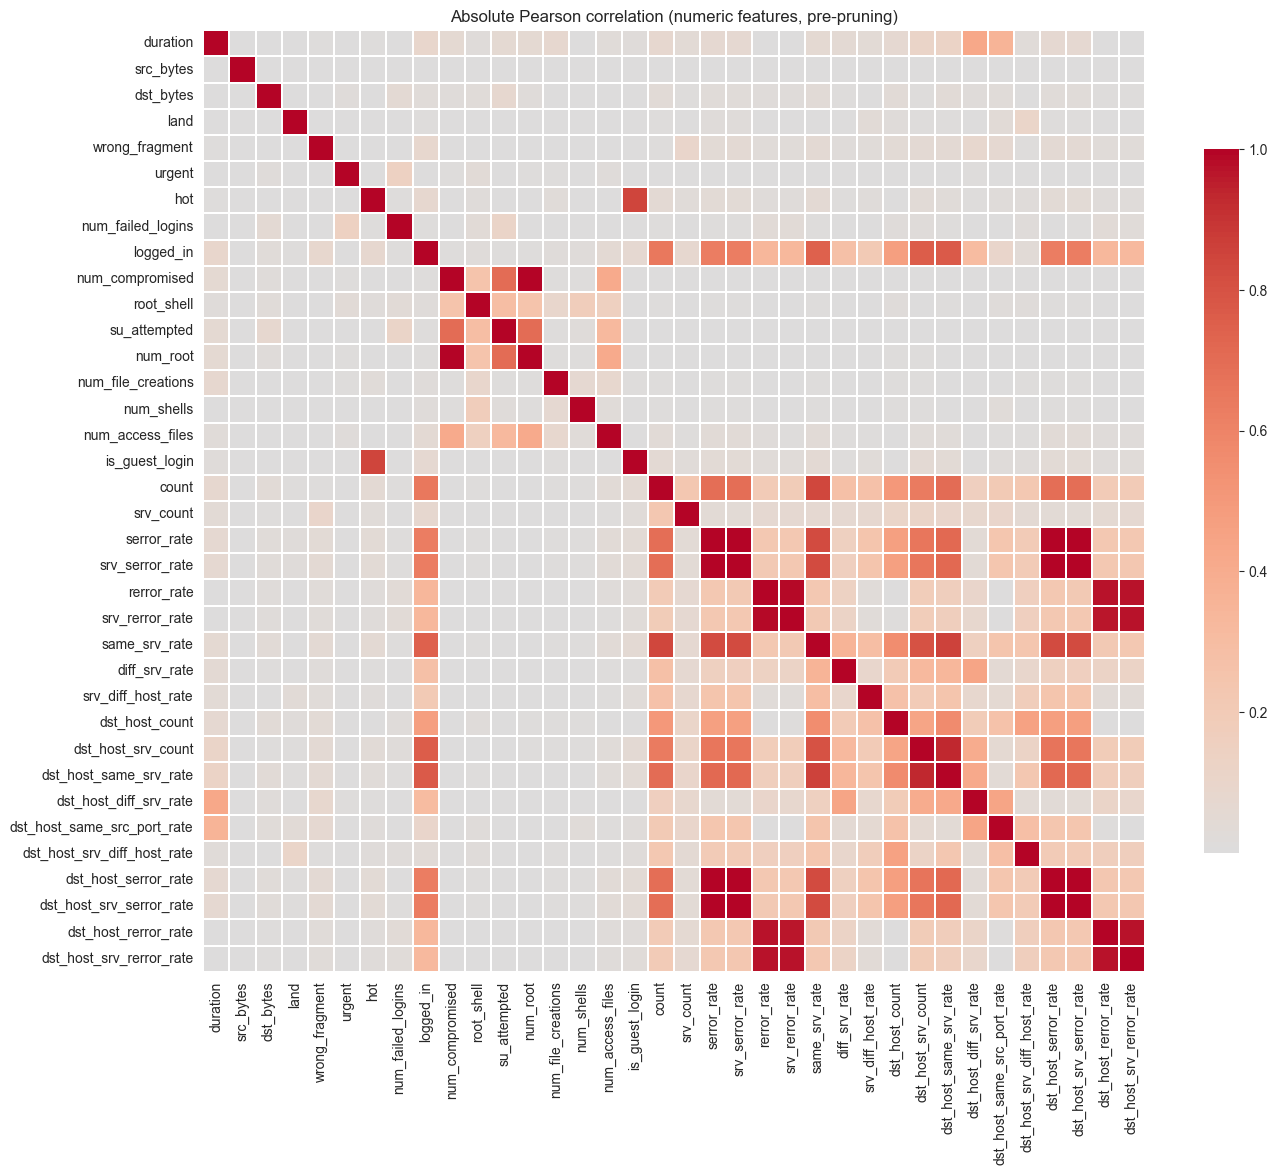

Saved: C:\Users\kitdu\OneDrive\Documents\network-guardian-ids\outputs\01_eda\correlation_heatmap.png


In [10]:
if not corr_matrix.empty:
    fig, ax = plt.subplots(figsize=(14, 12))
    sns.heatmap(
        corr_matrix,
        cmap="coolwarm",
        center=0.0,
        square=True,
        linewidths=0.2,
        cbar_kws={"shrink": 0.7},
        ax=ax,
    )
    ax.set_title("Absolute Pearson correlation (numeric features, pre-pruning)")
    plt.tight_layout()
    heatmap_path = PATHS.outputs / "01_eda" / "correlation_heatmap.png"
    plt.savefig(heatmap_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", heatmap_path)

In [11]:
log_columns = [c for c in data_prep.LOG_TRANSFORM_COLUMNS if c in kept_features]
work_df = data_prep.apply_log_transform(work_df, columns=log_columns)
work_df = work_df[kept_features + ["family"]]

print("Log-transformed columns:", log_columns)
print("Shape after transform :", work_df.shape)

Log-transformed columns: ['duration', 'src_bytes', 'dst_bytes']
Shape after transform : (145584, 32)


In [12]:
train_df, test_df = data_prep.stratified_split(work_df)

print(f"Train rows : {len(train_df)}")
print(f"Test rows  : {len(test_df)}")
print()
print("Train class distribution:")
print(train_df["family"].value_counts().sort_index())
print()
print("Test class distribution:")
print(test_df["family"].value_counts().sort_index())

Train rows : 109188
Test rows  : 36396

Train class distribution:
family
normal    65874
dos       40928
probe      1598
r2l         749
u2r          39
Name: count, dtype: int64

Test class distribution:
family
normal    21958
dos       13643
probe       532
r2l         250
u2r          13
Name: count, dtype: int64


In [13]:
encoding_result = encoding.fit_and_apply_encoders(
    train_df=train_df,
    test_df=test_df,
    output_dir=PATHS.processed,
)

train_encoded = encoding_result["train_encoded"]
test_encoded = encoding_result["test_encoded"]

print("Train shape (encoded):", train_encoded.shape)
print("Test shape  (encoded):", test_encoded.shape)
print()
print("Encoder artifacts:")
for name, path in encoding_result["encoder_paths"].items():
    print(f"  {name:<28} -> {path.name}")

Train shape (encoded): (109188, 44)
Test shape  (encoded): (36396, 44)

Encoder artifacts:
  frequency_service            -> encoder_service.pkl
  onehot_protocol_flag         -> encoder_onehot_protocol_flag.pkl


In [14]:
feature_names = [c for c in train_encoded.columns if c != "family"]

scaler, scaler_path = encoding.fit_and_persist_scaler(
    train_encoded=train_encoded,
    feature_columns=feature_names,
    output_dir=PATHS.processed,
)

print("Scaler fit on :", len(feature_names), "features")
print("Scaler saved  :", scaler_path.name)

Scaler fit on : 43 features
Scaler saved  : scaler_tabnet.pkl


In [15]:
# Feature name ordering.
save_json(feature_names, PATHS.processed / "feature_names.json")

# Class order.
save_json(list(data_prep.CLASS_ORDER), PATHS.processed / "class_order.json")

# Train and test matrices (features) and labels.
train_X = train_encoded[feature_names].to_numpy(dtype=np.float64)
test_X = test_encoded[feature_names].to_numpy(dtype=np.float64)
train_y = train_encoded["family"].astype(str).to_numpy(dtype='<U6')
test_y = test_encoded["family"].astype(str).to_numpy(dtype='<U6')

np.save(PATHS.processed / "X_train.npy", train_X)
np.save(PATHS.processed / "X_test.npy", test_X)
np.save(PATHS.processed / "y_train.npy", train_y)
np.save(PATHS.processed / "y_test.npy", test_y)

# Split contract.
data_prep.write_split_contract(
    train_df=train_encoded,
    test_df=test_encoded,
    feature_names=feature_names,
    contract_path=PATHS.processed / "split_indices.json",
)

print("Artifacts written to:", PATHS.processed)
for artifact in sorted(PATHS.processed.iterdir()):
    print(f"  {artifact.name}")

Artifacts written to: C:\Users\kitdu\OneDrive\Documents\network-guardian-ids\data\processed
  class_order.json
  correlation_matrix.csv
  encoder_onehot_protocol_flag.pkl
  encoder_service.pkl
  feature_names.json
  scaler_tabnet.pkl
  split_indices.json
  test_preencoded.csv
  train_preencoded.csv
  X_test.npy
  X_train.npy
  y_test.npy
  y_train.npy
